# 01 — EDA (CP1)
Flight summary, example flights, hover thrust fit. All logic is in `src/data/`; this notebook only calls it.
Run `pytest tests/test_frames.py -v -s` first — the frame decisions it checks are used here.

Outputs: `results/flight_summary.csv`, `results/hover_thrust_fit.json`, `results/example_flights.json`,
`results/figures/eda_example_flights.png`, `results/figures/eda_hover_thrust.png`.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
from src.data.load import segment_index, load_all
from src.data import frames as F, eda
print("quat convention:", F.QUAT_CONVENTION, "| acc is specific force:", F.ACC_IS_SPECIFIC_FORCE)
eda.FIGS.mkdir(parents=True, exist_ok=True)

Matplotlib is building the font cache; this may take a moment.


quat convention: xyzw_hamilton_body_to_world | acc is specific force: True


In [2]:
idx = segment_index()
df = eda.add_derived(load_all())          # first run parses all CSVs and caches to data/cache/
print(f"{len(idx)} segments, {idx.flight_id.nunique()} flights, {len(df):,} samples = {len(df)*eda.DT/60:.1f} min")

247 segments, 95 flights, 1,798,481 samples = 74.9 min


In [3]:
summary = eda.flight_summary(df, idx)
summary.to_csv("results/flight_summary.csv", index=False, float_format="%.4f")
summary.groupby("trajectory_type").agg(flights=("flight_id","size"), minutes=("duration_s", lambda s: s.sum()/60),
                                       max_speed=("max_speed","max"), max_acc=("max_acc_kin","max")).round(2)

,flights,minutes,max_speed,max_acc
trajectory_type,,,,
3d_circle,18,13.88,14.02,41.42
battery_test_circle,8,3.26,13.25,38.79
circle,4,2.77,13.47,41.21
cpc,9,5.20,14.97,36.27
ellipse,1,0.70,16.54,43.94
lemniscate,21,14.80,17.72,48.42
linear_oscillation,10,6.71,15.92,46.04
random_points,10,15.44,12.49,38.64
satellite,8,8.16,12.41,41.50


{'slow': '2021-02-03-16-47-27', 'medium': '2021-02-03-16-10-37', 'aggressive': '2021-02-23-17-35-26'}


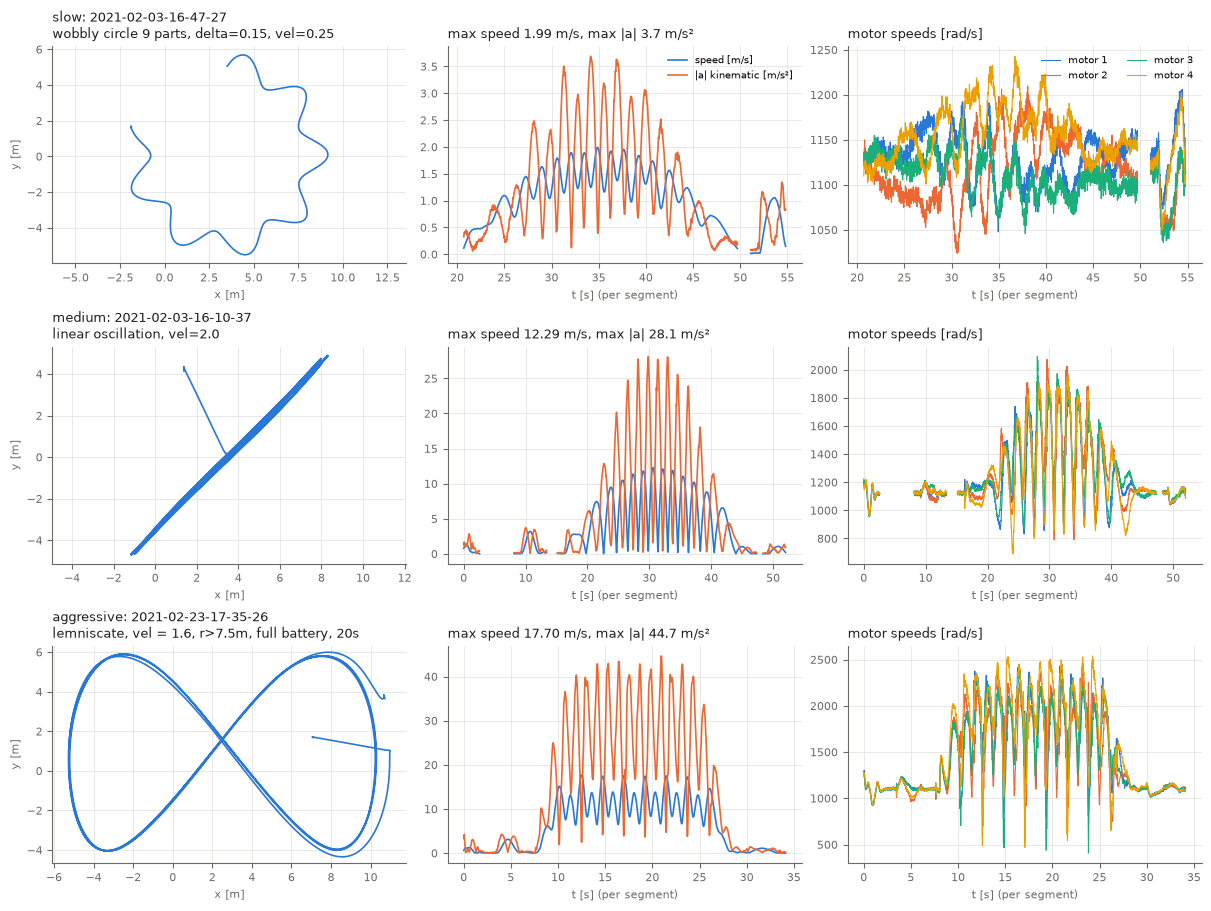

In [4]:
picks = eda.pick_example_flights(summary)
eda.save_json(picks, "example_flights.json")
print(picks)
eda.plot_example_flights(df, summary, picks, path="results/figures/eda_example_flights.png");

{'n_hover_samples': 118715, 'n_segments': 234, 'k_through_origin_N_per_rad2s2': 1.5071346607168943e-06, 'rmse_through_origin_N': 0.20307886237171127, 'r2_through_origin': -9.040555608168475, 'k_with_intercept': 1.1409931306591342e-07, 'intercept_N': 6.995686161741662, 'r2_with_intercept': 0.06101353413113941, 'thrust_N_range': [6.974914291534952, 7.891390695605426], 'sum_omega2_range': [4224136.05437324, 5471074.342142107], 'mass_kg': 0.772, 'k_across_flights': {'n_flights': 92, 'mean': 1.506083435982176e-06, 'std': 3.362543690746148e-08, 'min': 1.4519734919249315e-06, 'max': 1.5682415102110744e-06}, 'k_within_flight_rel_std_median': 0.0070320830286455145, 'k_median_per_day': {'2021-02-03': 1.4841659748834233e-06, '2021-02-05': 1.4703162821890591e-06, '2021-02-18': 1.4995377785839465e-06, '2021-02-23': 1.5519479559756544e-06}, 'corr_k_vbat': 0.2576900213308366, 'thrust_median_N': 7.569883220823129, 'note': 'R^2 is vs the mean of a near-constant hover thrust (~m*g); use rmse and k sprea

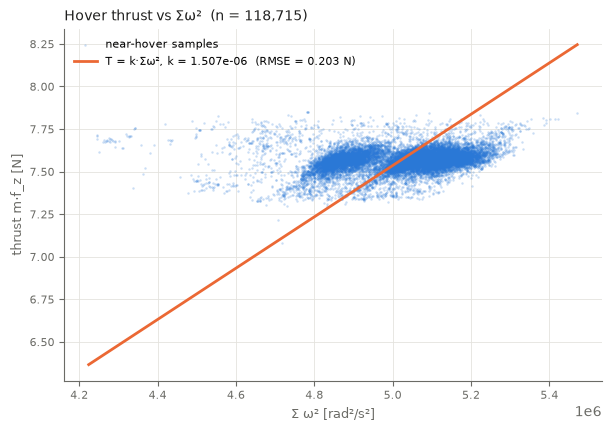

In [5]:
fit, pts = eda.hover_thrust_fit(df, idx)
eda.save_json(fit, "hover_thrust_fit.json")
print({k: v for k, v in fit.items() if k not in ("mask", "excluded")})
eda.plot_hover_fit(pts, fit, path="results/figures/eda_hover_thrust.png");